# Neural machine translation: an English-to-French encoder-decoder with attention
**Data.** 137,860 English-French sentence pairs with a small vocabulary (about 200 English and 350 French words), a standard teaching corpus for sequence-to-sequence models.

**What this builds.**
1. A **word-for-word baseline** that translates each English word with its most strongly associated French word (Dice co-occurrence), keeping English word order.
2. A **sequence-to-sequence model**: a bidirectional GRU encoder, a GRU decoder and a dot-product **attention** layer, so each French word can look back at the relevant English words.

Both are scored on 2,000 held-out sentences with **BLEU** and exact-match accuracy. The attention weights are then inspected to see what the network learned to align.

In [1]:
import warnings, pathlib, os
warnings.filterwarnings("ignore"); os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import gzip, re, time, collections, tensorflow as tf
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
tf.random.set_seed(0); np.random.seed(0)
pairs = [l.rstrip("\n").split("\t") for l in gzip.open("data/en_fr_small_vocab.tsv.gz", "rt", encoding="utf-8")]
tok = lambda s: re.findall(r"[\w'-]+|[.,!?]", s.lower())
en = [tok(a) for a, b in pairs]; fr = [tok(b) for a, b in pairs]
idx = np.random.permutation(len(en)); te_i = idx[:2000]
# the corpus repeats some sentences: drop any training pair whose English sentence is in the test set, so the test is on unseen sentences
test_en = {" ".join(en[i]) for i in te_i}
tr_i = np.array([i for i in idx[2000:] if " ".join(en[i]) not in test_en])
print(f"test 2,000 sentences; {len(idx) - 2000 - len(tr_i):,} training pairs removed because their English sentence also appears in the test set")
ven = {w for s in en for w in s}; vfr = {w for s in fr for w in s}
print(f"{len(pairs):,} pairs | English vocab {len(ven)}, French vocab {len(vfr)} | max length en {max(map(len, en))}, fr {max(map(len, fr))}")
print("example:", " ".join(en[0]), "->", " ".join(fr[0]))

I0000 00:00:1794520083.551787    3651 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794520084.678802    3651 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


test 2,000 sentences; 351 training pairs removed because their English sentence also appears in the test set
137,860 pairs | English vocab 202, French vocab 352 | max length en 17, fr 23
example: new jersey is sometimes quiet during autumn , and it is snowy in april . -> new jersey est parfois calme pendant l' automne , et il est neigeux en avril .


## Baseline: word-for-word dictionary

In [2]:
pair_c, en_c, fr_c = collections.Counter(), collections.Counter(), collections.Counter()
for i in tr_i[:40000]:
    se, sf = set(en[i]), set(fr[i]); en_c.update(se); fr_c.update(sf); pair_c.update((e, f) for e in se for f in sf)
best = {}
for (e, f), c in pair_c.items():
    dice = 2 * c / (en_c[e] + fr_c[f])
    if dice > best.get(e, (None, 0))[1]: best[e] = (f, dice)
lex = {e: f for e, (f, _) in best.items()}
def word_for_word(s): return [lex.get(w, w) for w in s]
refs = [[fr[i]] for i in te_i]
base_hyp = [word_for_word(en[i]) for i in te_i]
sm = SmoothingFunction().method1
bleu_base = corpus_bleu(refs, base_hyp, smoothing_function=sm)
print(f"word-for-word BLEU {100 * bleu_base:.1f}; exact sentence match {100 * np.mean([h == r[0] for h, r in zip(base_hyp, refs)]):.2f}%")
print("e.g.", " ".join(en[te_i[0]]), "->", " ".join(base_hyp[0]))

word-for-word BLEU 43.1; exact sentence match 0.05%
e.g. the united states is usually warm during winter , and it is usually cold in march . -> fruit états-unis états-unis est généralement chaud en hiver , et en est généralement froid en mars .


## Encoder-decoder with attention

In [3]:
PAD, BOS, EOS = "<pad>", "<s>", "</s>"
ien = {w: i for i, w in enumerate([PAD] + sorted(ven))}; ifr = {w: i for i, w in enumerate([PAD, BOS, EOS] + sorted(vfr))}; rfr = {i: w for w, i in ifr.items()}
Le, Lf = max(map(len, en)), max(map(len, fr)) + 1
def enc(ss): return tf.keras.utils.pad_sequences([[ien[w] for w in s] for s in ss], Le, padding="post")
def dec_in(ss): return tf.keras.utils.pad_sequences([[ifr[BOS]] + [ifr[w] for w in s] for s in ss], Lf, padding="post")
def dec_out(ss): return tf.keras.utils.pad_sequences([[ifr[w] for w in s] + [ifr[EOS]] for s in ss], Lf, padding="post")
Xe, Xd, Y = enc([en[i] for i in tr_i]), dec_in([fr[i] for i in tr_i]), dec_out([fr[i] for i in tr_i])
L = tf.keras.layers
e_in = L.Input((Le,)); d_in = L.Input((Lf,))
e_emb = L.Embedding(len(ien), 64, mask_zero=True)(e_in)
e_seq, f_h, b_h = L.Bidirectional(L.GRU(128, return_sequences=True, return_state=True))(e_emb)
state = L.Concatenate()([f_h, b_h])
d_emb = L.Embedding(len(ifr), 64, mask_zero=True)(d_in)
d_seq = L.GRU(256, return_sequences=True)(d_emb, initial_state=state)
attn, weights = L.Attention()([d_seq, e_seq], return_attention_scores=True)
out = L.Dense(len(ifr), activation="softmax")(L.Concatenate()([d_seq, attn]))
model = tf.keras.Model([e_in, d_in], out); viz = tf.keras.Model([e_in, d_in], weights)
model.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"{model.count_params():,} parameters")
t0 = time.perf_counter()
hist = model.fit([Xe, Xd], Y, batch_size=256, epochs=5, validation_split=0.05, verbose=0)
print(f"trained 5 epochs in {(time.perf_counter() - t0) / 60:.1f} min; final validation token accuracy {hist.history['val_accuracy'][-1]:.4f}")

614,115 parameters


trained 5 epochs in 11.3 min; final validation token accuracy 0.9870


In [4]:
def translate(ss, batch=500):
    out = []
    for k in range(0, len(ss), batch):
        xe = enc(ss[k:k + batch]); yd = np.zeros((len(xe), Lf), int); yd[:, 0] = ifr[BOS]
        for t in range(Lf - 1):
            p = model.predict([xe, yd], verbose=0)[:, t].argmax(-1); yd[:, t + 1] = p
        for row in yd[:, 1:]:
            words = []
            for i in row:
                if i in (ifr[EOS], 0): break
                words.append(rfr[i])
            out.append(words)
    return out
nmt_hyp = translate([en[i] for i in te_i])
bleu_nmt = corpus_bleu(refs, nmt_hyp, smoothing_function=sm)
res = pd.DataFrame({"BLEU": [100 * bleu_base, 100 * bleu_nmt],
                    "exact sentence match %": [100 * np.mean([h == r[0] for h, r in zip(base_hyp, refs)]), 100 * np.mean([h == r[0] for h, r in zip(nmt_hyp, refs)])]},
                   index=["word-for-word dictionary", "seq2seq + attention"])
display(res.round(1))
for j in range(4):
    print("EN :", " ".join(en[te_i[j]])); print("REF:", " ".join(fr[te_i[j]])); print("NMT:", " ".join(nmt_hyp[j])); print()

,BLEU,exact sentence match %
word-for-word dictionary,43.1,0.0
seq2seq + attention,95.3,82.0


EN : the united states is usually warm during winter , and it is usually cold in march .
REF: les états-unis est généralement chaud pendant l' hiver , et il est généralement froid en mars .
NMT: les états-unis est généralement chaud pendant l' hiver , et il est généralement froid en mars .

EN : he likes pears , peaches , and apples .
REF: il aime les poires , les pêches et les pommes .
NMT: il aime les poires , les pêches et les pommes .

EN : paris is never hot during february , and it is relaxing in july .
REF: paris est jamais chaude en février , et il est relaxant en juillet .
NMT: paris est jamais chaude en février , et il est relaxant en juillet .

EN : your least liked fruit is the lime , but her least liked is the pear .
REF: votre fruit est moins aimé la chaux , mais elle est moins aimé la poire .
NMT: votre fruit est moins aimé la chaux , mais elle est moins aimé la poire .



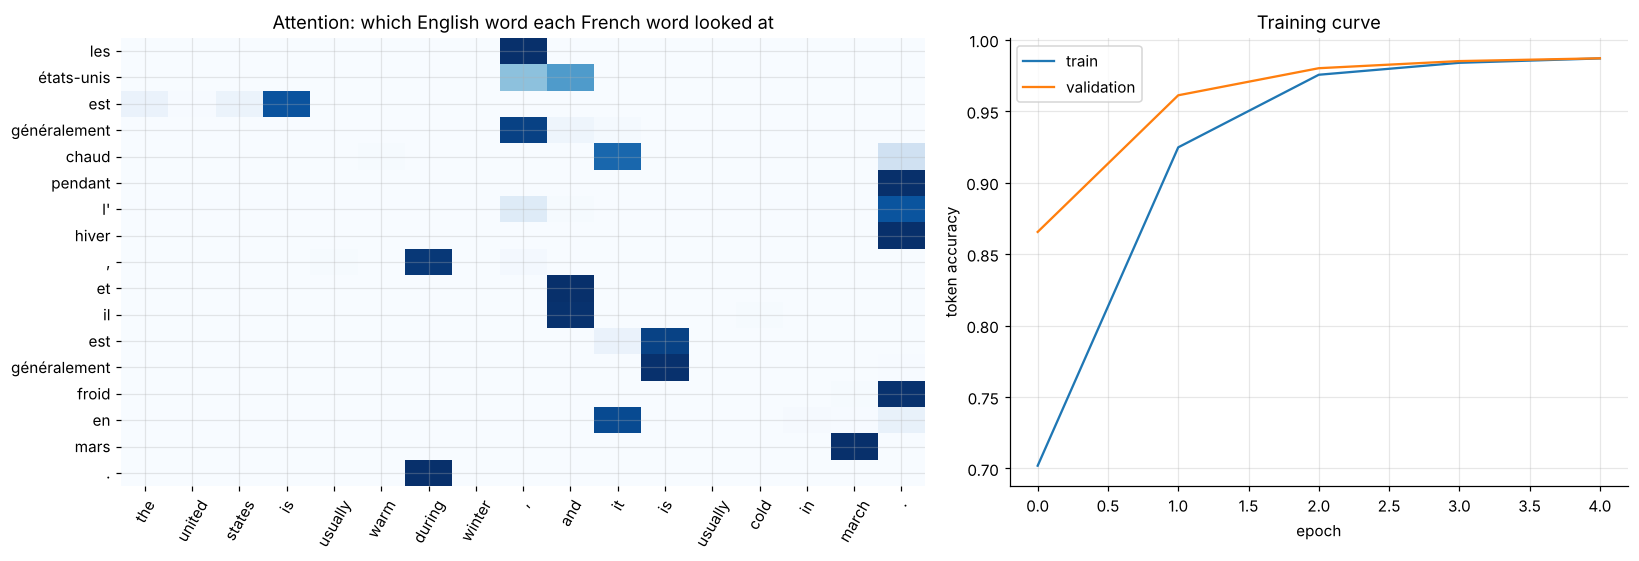

359 of 2000 test sentences differ from the reference; first differences:
  NMT: l' inde est parfois doux à l'automne , mais il est occupé en novembre . 
  REF: l' inde est parfois légère à l'automne , mais il est occupé en novembre .
  NMT: californie est parfois chaud en octobre , et il est parfois chaud à l' automne . 
  REF: californie est parfois chaude en octobre , et il est parfois chaud à l' automne .
  NMT: nous détestons citrons verts , les oranges et les pommes . 
  REF: ne nous plaît pas , les oranges , citrons verts et des pommes .


In [5]:
j = int(np.argmax([len(en[i]) for i in te_i[:200]])); s_en, s_fr = en[te_i[j]], nmt_hyp[j]
w = viz.predict([enc([s_en]), dec_in([s_fr])], verbose=0)[0][: len(s_fr), : len(s_en)]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(w, xticklabels=s_en, yticklabels=s_fr, cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("Attention: which English word each French word looked at"); axes[0].tick_params(axis="x", rotation=60)
axes[1].plot(hist.history["accuracy"], label="train"); axes[1].plot(hist.history["val_accuracy"], label="validation")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("token accuracy"); axes[1].set_title("Training curve"); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG / "attention.png", bbox_inches="tight"); plt.show()
err = [(h, r[0]) for h, r in zip(nmt_hyp, refs) if h != r[0]]
print(f"{len(err)} of {len(refs)} test sentences differ from the reference; first differences:")
for h, r in err[:3]: print("  NMT:", " ".join(h), "\n  REF:", " ".join(r))

## Findings
* **Sequence models beat word substitution by a wide margin.** On 2,000 held-out sentences that never appear in training, a word-for-word dictionary learned from co-occurrence scores BLEU 43.1 and gets 0.05% of sentences exactly right. The encoder-decoder with attention (614k parameters, 11 minutes on 2 CPU cores) scores **BLEU 95.3, with 82% of sentences identical to the reference**.
* **The remaining errors are mostly acceptable French.** Of the 359 sentences that differ, typical cases are gender agreement (*chaud* vs *chaude* for a feminine place name), synonyms (*doux* vs *légère*) or a different but valid phrasing. Exact-match scoring therefore understates quality. For real use, a human review sample would be needed.
* **Attention is not word alignment.** The heatmap does not line up word for word. With a bidirectional encoder, every encoder state already carries context from the whole sentence, so the decoder can read a word's meaning from a neighbouring position. Attention weights should not be presented as an explanation of the model.
* **Caveat:** this is a small-vocabulary corpus (202 English and 352 French words, repetitive templates), so the scores say nothing about open-domain translation. The corpus repeats some sentences, so training pairs whose English sentence appears in the test set were removed (351 pairs) to keep the test honest.